<a href="https://colab.research.google.com/github/davidfwallace/metastase-pcam/blob/main/notebooks/03_transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — Transfer learning

ResNet-18 pré-treinada na ImageNet contra a CNN treinada do zero no notebook 02 (AUC de validação ~0,95).

**Configurações (3 sementes cada):**
- `A_aleatoria`: pesos aleatórios, rede toda treinada (controle);
- `B_so_cabeca`: pré-treinada, só a cabeça treinada;
- `C_fine_tuning`: pré-treinada, rede toda ajustada (fine-tuning);
- `D_fine_tuning_cor`: a C com aumento de cor suave;
- `C_fine_tuning_3ep` e `D_fine_tuning_cor_3ep`: as mesmas, com 3 épocas em vez de 10 — criadas depois que a primeira rodada mostrou sobreajuste a partir da época 3;
- `D_fine_tuning_corantes_3ep`: aumento por corantes (variação de hematoxilina e eosina, ±50%), para testar se o efeito nulo da cor vinha da força suave demais. Uma versão mais forte do aumento por canais foi rejeitada antes de treinar, porque gerava cores impossíveis em H&E (verde, marrom; ver a figura).

Antes, um teste de infraestrutura: carregar o treino inteiro na RAM para acelerar a leitura.

In [1]:
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import psutil
import torch

print("GPU:", torch.cuda.get_device_name(0))

# Código do projeto: clona na primeira vez, atualiza nas seguintes
REPO = Path("/content/metastase-pcam")
if REPO.exists():
    subprocess.run(["git", "-C", str(REPO), "pull"], check=True)
else:
    subprocess.run(["git", "clone", "https://github.com/davidfwallace/metastase-pcam.git", str(REPO)],
                   check=True)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from google.colab import drive
drive.mount("/content/drive")

RAIZ = Path("/content/drive/MyDrive/metastase-pcam")
DATA_DIR = RAIZ / "data"
REPORTS_DIR = RAIZ / "reports"
CACHE_DIR = Path("/content/cache")

def ram_livre():
    return psutil.virtual_memory().available / 1e9

print(f"RAM total: {psutil.virtual_memory().total / 1e9:.1f} GB | livre: {ram_livre():.1f} GB")

GPU: NVIDIA L4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RAM total: 56.9 GB | livre: 53.9 GB


In [2]:
from src.dados import preparar_split
from src.dataset import carregador, preparar_lote

X_treino_mm, y_treino = preparar_split(DATA_DIR, "train", CACHE_DIR)
X_valid_mm, y_valid = preparar_split(DATA_DIR, "valid", CACHE_DIR)

def medir_velocidade(carregador_teste, n_lotes=200):
    """Imagens/s de leitura + preparo na GPU, sem contar a subida dos workers."""
    lotes = iter(carregador_teste)
    next(lotes)
    torch.cuda.synchronize()
    inicio = time.time()
    for _ in range(n_lotes):
        imagens, rotulos = next(lotes)
        preparar_lote(imagens.cuda(non_blocking=True), aumento=True)
    torch.cuda.synchronize()
    return n_lotes * 256 / (time.time() - inicio)

velocidade = medir_velocidade(carregador(X_treino_mm, y_treino, 256, embaralhar=True, num_workers=2))
print(f"memmap, 2 workers: ~{velocidade:,.0f} imagens/s")
print(f"RAM livre: {ram_livre():.1f} GB")

memmap, 2 workers: ~49,051 imagens/s
RAM livre: 53.5 GB


In [3]:
from src.dados import para_ram_se_couber

X_treino = para_ram_se_couber(X_treino_mm)
X_valid = para_ram_se_couber(X_valid_mm)
onde = "memmap (disco)" if isinstance(X_treino, np.memmap) else "RAM"
carregador_treino = carregador(X_treino, y_treino, 256, embaralhar=True)
carregador_valid = carregador(X_valid, y_valid, 256, embaralhar=False)
print(f"Treino em: {onde} | RAM livre: {ram_livre():.1f} GB")
print(f"Leitura: ~{medir_velocidade(carregador_treino):,.0f} imagens/s")

Treino em: RAM | RAM livre: 45.3 GB
Leitura: ~76,968 imagens/s


**Teste: treino inteiro na RAM.**
- **Colab gratuito (13,6 GB):** não cabe. Depois de carregar treino e validação (~8,2 GB), restaram 0,4 GB livres, a leitura caiu para ~466 imagens/s e a sessão caiu ao criar os workers.
- **Colab com RAM alta (56,9 GB):** cabe com folga (40 GB livres depois). Na RAM: ~70 mil imagens/s com 0 workers e ~61 mil com 2. Os workers só somam custo de comunicação quando os dados já estão na memória.
- **A surpresa:** com RAM alta, até o memmap chega a ~53 mil imagens/s, contra ~1,1–1,9 mil no gratuito. Com memória sobrando, o sistema provavelmente mantém o arquivo inteiro em cache. O gargalo do notebook 02 era falta de memória para o cache, não o disco em si.

**Decisão:** carregar na RAM quando couber (0 workers); memmap com 2 workers quando não couber. Com qualquer uma das duas no ambiente de RAM alta, a leitura deixa de ser o gargalo: daqui em diante, quem limita é a GPU.

## ResNet-18: as quatro configurações

In [4]:
from torch import nn

from src.modelos import ResNetPCam

imagens, rotulos = next(iter(carregador_treino))
imagens, rotulos = imagens.cuda(), rotulos.cuda()
x = preparar_lote(imagens, aumento=False)

for nome, pretreinada, congelar in [("A. aleatória", False, False),
                                    ("B. só a cabeça", True, True),
                                    ("C. fine-tuning", True, False)]:
    torch.manual_seed(42)
    modelo = ResNetPCam(pretreinada=pretreinada, congelar=congelar).cuda()
    total = sum(p.numel() for p in modelo.parameters())
    treinaveis = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    modelo.train()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        logits = modelo(x)
    perda = nn.BCEWithLogitsLoss()(logits.float(), rotulos)
    print(f"{nome}: {total:,} parâmetros, {treinaveis:,} treináveis | "
          f"saída {tuple(logits.shape)} | perda inicial {perda:.3f}")

# Velocidade de treino da configuração C (a mais pesada): 30 passos completos
otimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-4)
escalador = torch.amp.GradScaler("cuda")
for passo in range(31):
    if passo == 1:  # o primeiro passo inclui a preparação da GPU; fica fora da conta
        torch.cuda.synchronize()
        inicio = time.time()
    with torch.autocast("cuda", dtype=torch.float16):
        perda = nn.BCEWithLogitsLoss()(modelo(preparar_lote(imagens, aumento=True)).float(), rotulos)
    otimizador.zero_grad(set_to_none=True)
    escalador.scale(perda).backward()
    escalador.step(otimizador)
    escalador.update()
torch.cuda.synchronize()
por_segundo = 30 * 256 / (time.time() - inicio)
print(f"Treino da ResNet-18 na L4: ~{por_segundo:,.0f} imagens/s "
      f"(~{len(y_treino) / por_segundo:.0f} s por época)")

A. aleatória: 11,177,025 parâmetros, 11,177,025 treináveis | saída (256,) | perda inicial 0.711
B. só a cabeça: 11,177,025 parâmetros, 513 treináveis | saída (256,) | perda inicial 0.770
C. fine-tuning: 11,177,025 parâmetros, 11,177,025 treináveis | saída (256,) | perda inicial 0.777
Treino da ResNet-18 na L4: ~6,843 imagens/s (~38 s por época)


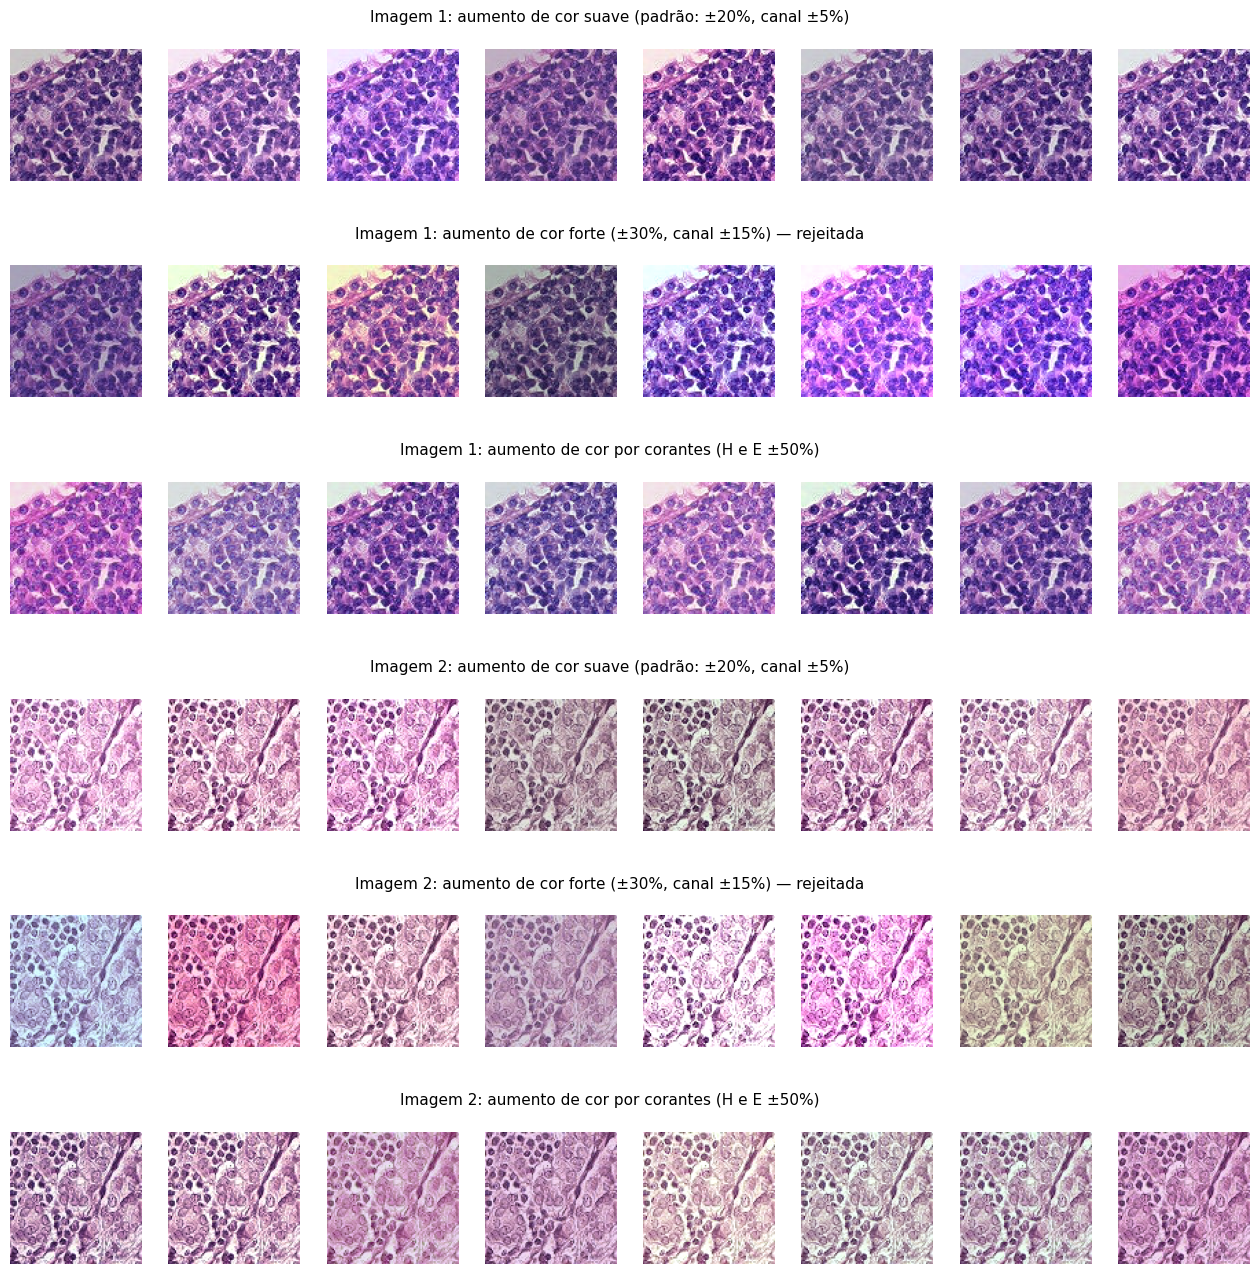

In [5]:
import matplotlib.pyplot as plt

from src.dataset import DESVIO, MEDIA

FORTE = dict(forca=0.3, desvio_canal=0.15)  # brilho/contraste/saturação ±30%, ganho por canal ±15%

def para_exibir(tensor):
    media = torch.tensor(MEDIA).view(3, 1, 1)
    desvio = torch.tensor(DESVIO).view(3, 1, 1)
    return (tensor.cpu() * desvio + media).clamp(0, 1).permute(1, 2, 0).numpy()

fig = plt.figure(figsize=(16, 13))
faixas = iter(fig.subfigures(6, 1))
for i in range(2):  # duas imagens diferentes
    copias = torch.from_numpy(np.array(X_treino[i]))[None].repeat(8, 1, 1, 1).cuda()
    for nome, cor in [("suave (padrão: ±20%, canal ±5%)", True),
                      ("forte (±30%, canal ±15%) — rejeitada", FORTE),
                      ("por corantes (H e E ±50%)", "corantes")]:
        faixa = next(faixas)
        faixa.suptitle(f"Imagem {i + 1}: aumento de cor {nome}", fontsize=11)
        for ax, imagem in zip(faixa.subplots(1, 8), preparar_lote(copias, aumento=False, cor=cor)):
            ax.imshow(para_exibir(imagem))
            ax.axis("off")
fig.savefig(REPORTS_DIR / "figures" / "03_aumento_de_cor.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
from src.treino import treinar

CONFIGURACOES = {
    "A_aleatoria":           dict(pretreinada=False, congelar=False, lr=1e-3),
    "B_so_cabeca":           dict(pretreinada=True,  congelar=True,  lr=1e-3),
    "C_fine_tuning":         dict(pretreinada=True,  congelar=False, lr=1e-4),
    "D_fine_tuning_cor":     dict(pretreinada=True,  congelar=False, lr=1e-4, cor=True),
    "C_fine_tuning_3ep":     dict(pretreinada=True,  congelar=False, lr=1e-4, epocas=3),
    "D_fine_tuning_cor_3ep": dict(pretreinada=True,  congelar=False, lr=1e-4, cor=True, epocas=3),
    "D_fine_tuning_corantes_3ep": dict(pretreinada=True, congelar=False, lr=1e-4, cor="corantes", epocas=3),
}
N_EPOCAS = 10

def rodar(nome, semente):
    """Treina uma configuração com uma semente; checkpoints em checkpoints/<nome>_s<semente>."""
    config = CONFIGURACOES[nome]
    print(f"\n=== {nome}, semente {semente} ===")
    torch.manual_seed(semente)
    modelo = ResNetPCam(pretreinada=config["pretreinada"], congelar=config["congelar"]).cuda()
    return treinar(modelo, carregador_treino, carregador_valid,
                   n_epocas=config.get("epocas", N_EPOCAS),
                   pasta_checkpoints=RAIZ / "checkpoints" / f"{nome}_s{semente}",
                   lr=config["lr"], cor=config.get("cor", False))

historicos = {}
for semente in (0, 1, 2):              # semente por fora: cada rodada completa fica pronta antes da próxima
    for nome in CONFIGURACOES:
        historicos[(nome, semente)] = rodar(nome, semente)


=== A_aleatoria, semente 0 ===
Retomando depois da época 10. Épocas já feitas:
Época  1/10 | lr 1.00e-03 | treino 0.313 | valid perda 0.356 AUC 0.925 acurácia 0.842 | 40 s
Época  2/10 | lr 9.76e-04 | treino 0.214 | valid perda 0.545 AUC 0.934 acurácia 0.814 | 40 s
Época  3/10 | lr 9.05e-04 | treino 0.172 | valid perda 0.531 AUC 0.913 acurácia 0.800 | 40 s
Época  4/10 | lr 7.94e-04 | treino 0.152 | valid perda 0.505 AUC 0.920 acurácia 0.829 | 40 s
Época  5/10 | lr 6.55e-04 | treino 0.134 | valid perda 0.302 AUC 0.951 acurácia 0.879 | 40 s
Época  6/10 | lr 5.00e-04 | treino 0.120 | valid perda 0.354 AUC 0.947 acurácia 0.870 | 40 s
Época  7/10 | lr 3.45e-04 | treino 0.107 | valid perda 0.490 AUC 0.947 acurácia 0.834 | 40 s
Época  8/10 | lr 2.06e-04 | treino 0.094 | valid perda 0.496 AUC 0.945 acurácia 0.838 | 40 s
Época  9/10 | lr 9.55e-05 | treino 0.085 | valid perda 0.478 AUC 0.940 acurácia 0.846 | 40 s
Época 10/10 | lr 2.45e-05 | treino 0.079 | valid perda 0.462 AUC 0.947 acurácia 0.8

In [7]:
import pandas as pd

linhas = [dict(config=nome, semente=semente, **registro)
          for (nome, semente), historico in historicos.items() for registro in historico]
pd.DataFrame(linhas).to_csv(REPORTS_DIR / "03_historicos.csv", index=False)
print(f"Salvo: {len(linhas)} linhas em 03_historicos.csv")

Salvo: 147 linhas em 03_historicos.csv


                            auc_media  auc_desvio  perda_media  acuracia_media
config                                                                        
C_fine_tuning_3ep              0.9592      0.0009       0.3569          0.8791
D_fine_tuning_cor_3ep          0.9557      0.0042       0.3330          0.8815
D_fine_tuning_corantes_3ep     0.9554      0.0037       0.3421          0.8788
C_fine_tuning                  0.9545      0.0022       0.5517          0.8640
D_fine_tuning_cor              0.9534      0.0029       0.4501          0.8726
A_aleatoria                    0.9478      0.0034       0.4572          0.8575
B_so_cabeca                    0.9011      0.0007       0.4019          0.8183


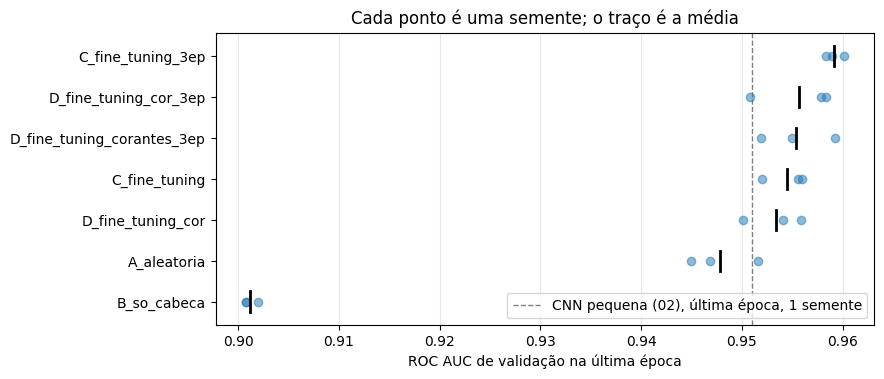

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

resultados = pd.read_csv(REPORTS_DIR / "03_historicos.csv")
# A última época de cada treino (configuração × semente)
finais = resultados.loc[resultados.groupby(["config", "semente"])["epoca"].idxmax()]
resumo = (finais.groupby("config")
          .agg(auc_media=("valid_auc", "mean"), auc_desvio=("valid_auc", "std"),
               perda_media=("valid_perda", "mean"), acuracia_media=("valid_acuracia", "mean"))
          .sort_values("auc_media", ascending=False))
resumo.round(4).to_csv(REPORTS_DIR / "03_resumo_configuracoes.csv")
print(resumo.round(4).to_string())

ordem = resumo.index[::-1]  # a melhor configuração fica no topo
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for linha, config in enumerate(ordem):
    aucs = finais.loc[finais["config"] == config, "valid_auc"]
    ax.scatter(aucs, [linha] * len(aucs), color="tab:blue", alpha=0.5, s=36, zorder=3)
    ax.plot([aucs.mean()] * 2, [linha - 0.25, linha + 0.25], color="black", lw=2, zorder=4)
ax.axvline(0.951, color="gray", ls="--", lw=1, label="CNN pequena (02), última época, 1 semente")
ax.set_yticks(range(len(ordem)), ordem)
ax.set(xlabel="ROC AUC de validação na última época",
       title="Cada ponto é uma semente; o traço é a média")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")
fig.savefig(REPORTS_DIR / "figures" / "03_configuracoes.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusões

**Modelo escolhido: `C_fine_tuning_3ep`** — ResNet-18 pré-treinada, fine-tuning de 3 épocas, sem aumento de cor. AUC de validação **0,959 ± 0,001** (média ± desvio de 3 sementes, última época).

**Método.** Cada configuração foi treinada com 3 sementes e comparada pela AUC da **última** época: com o agendamento cosseno terminando perto de zero, é o modelo final, sem nenhuma escolha feita na validação. Os desvios entre sementes ficaram entre 0,001 e 0,004 — bem menores que a oscilação de ±0,01 entre épocas vista no notebook 02.

**O que os experimentos mostraram:**
- **Só treinar a cabeça (`B_so_cabeca`) é claramente pior (0,901).** As características da ImageNet servem para tecido (bem acima da régua de 0,810), mas não bastam: perdas de treino e validação próximas indicam falta de capacidade, não sobreajuste.
- **Uma rede maior, sozinha, não ajuda.** A ResNet-18 treinada do zero (`A_aleatoria`, 0,948) empata com a CNN pequena do 02 (0,951) e oscila muito durante o treino.
- **O pré-treino ajuda, mas pouco:** +0,007 em 10 épocas (`C_fine_tuning` contra `A_aleatoria`), cerca de 2 vezes o desvio. O ganho mais claro é velocidade (AUC 0,955 já na primeira época) e estabilidade.
- **Fine-tuning curto é melhor que longo.** Com 10 épocas a rede sobreajusta (perda de validação 0,55); com 3, a AUC sobe para 0,959 e a perda cai para 0,36.
- **O aumento de cor não melhorou a AUC**, em nenhuma das duas formas testadas:
  - **por canais, suave** (`D_fine_tuning_cor_3ep`, 0,956): reduz o excesso de confiança no treino longo, mas não muda a ordenação;
  - **por corantes, forte** (`D_fine_tuning_corantes_3ep`, 0,955): variação de hematoxilina e eosina de ±50%, conferida visualmente como realista.
  - Uma versão forte do aumento por canais (±15% por canal) foi **rejeitada antes de treinar**, por gerar cores impossíveis em H&E (verde, marrom; ver `03_aumento_de_cor.png`).

**Ressalvas.**
- As sementes medem o acaso do treino, não o da validação: todas foram avaliadas nas mesmas lâminas, e diferenças de 0,003–0,004 podem mudar de ordem no teste.
- O número de épocas (3) foi escolhido olhando a validação da semente 0; as sementes 1 e 2 confirmaram.
- Fine-tuning (lr 0,0001) e treino do zero (lr 0,001) usam taxas de aprendizado diferentes, cada uma a usual para a sua situação.
- O aumento de cor costuma valer mais quando o modelo encontra coloração nova (lâminas de outro laboratório). Se a validação da PCam mistura os mesmos hospitais do treino, ela não traz essa variação — num teste externo, o resultado poderia ser outro.

**Infraestrutura.** No Colab gratuito o treino não cabe na RAM; com RAM alta, a leitura deixa de ser gargalo (~70 mil imagens/s) e cada época da ResNet-18 leva ~40 s na L4.

**Próximo passo (notebook 04):** avaliar `C_fine_tuning_3ep` no teste, uma única vez — possivelmente como ensemble das 3 sementes —, escolher o limiar priorizando sensibilidade, e inspecionar o que a rede olha com Grad-CAM.

In [9]:
# Para deixar um treino longo rodando sozinho, descomente a linha abaixo: ela desliga o ambiente
# no fim e para de gastar unidades. Fica comentada para não encerrar a sessão num "Executar tudo".
# from google.colab import runtime; runtime.unassign()